# 05 — Explicabilité des modèles : Grad-CAM et Integrated Gradients

**Projet :** classification de sept catégories de lésions cutanées avec ResNet50, EfficientNet-B0 et ViT-B/16.

**Objectif du notebook :** Visualiser les régions de l'image associées aux scores des classes prédites, puis examiner les prédictions correctes et les erreurs. Ces visualisations ne constituent ni une segmentation de lésion, ni une preuve de pertinence clinique.

Expliquer les prédictions de deux architectures déjà entraînées : **EfficientNet-B0** (Grad-CAM) et **ViT-B/16** (Integrated Gradients). Les architectures ont été sélectionnées d'après le classement sur **Validation**, sans utiliser le Test Set pour la sélection. Les exemples analysés proviennent du **Test Set indépendant au niveau `lesion_id`**.

In [1]:
from pathlib import Path
import json
import random
import gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torchvision import transforms, models
from PIL import Image
from torch.utils.data import Dataset, DataLoader

# 1. Reproductibilité
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# 2. Dataset HAM10000
DATA_DIR = Path(
    "/kaggle/input/datasets/imaneelqoraychy/ham-dataset/HAM10000"
)

IMAGES_DIR = DATA_DIR / "images"
METADATA_PATH = DATA_DIR / "HAM10000_metadata.csv"

# 3. Partitions du notebook 02
PREPROCESSING_DIR = Path(
    "/kaggle/input/datasets/imaneelqoraychy/ham10000-datasplits/ham10000_Portfolio"
)

SPLITS_DIR = PREPROCESSING_DIR / "splits"
CONFIG_PATH = PREPROCESSING_DIR / "data_config.json"

# 4. Checkpoints du notebook 03
MODELS_DIR = Path(
    "/kaggle/input/notebooks/imaneelqoraychy/03-modelstraining/ham10000_Portfolio/models"
)

MODEL_PATHS = {
    "resnet50": MODELS_DIR / "resnet50_best.pt",
    "efficientnet_b0": MODELS_DIR / "efficientnet_b0_best.pt",
    "vit_b_16": MODELS_DIR / "vit_b_16_best.pt"
}

# 5. Résultats du notebook 04
METRICS_DIR = Path(
    "/kaggle/input/notebooks/imaneelqoraychy/04-modelsevaluation/ham10000_evaluation/metrics"
)

SELECTION_PATH = METRICS_DIR / "selected_model.json"
COMPARISON_PATH = METRICS_DIR / "test_comparison.csv"

# 6. Paramètres identiques aux notebooks précédents
CLASSES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]

CLASS_TO_IDX = {
    classe: i for i, classe in enumerate(CLASSES)
}

IMAGE_SIZE = 224

MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

# 7. Dossier de sortie XAI
OUTPUT_ROOT = Path("/kaggle/working/ham10000_Portfolio")
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

# 8. Vérifier les fichiers nécessaires
required_files = {
    "Métadonnées": METADATA_PATH,
    "Train": SPLITS_DIR / "train.csv",
    "Validation": SPLITS_DIR / "val.csv",
    "Test": SPLITS_DIR / "test.csv",
    "Configuration": CONFIG_PATH,
    "Sélection": SELECTION_PATH,
    "Comparaison": COMPARISON_PATH,
    **MODEL_PATHS
}

print("PyTorch :", torch.__version__)
print("Device :", DEVICE)

for name, path in required_files.items():
    print(f"{name} :", "OK" if path.is_file() else "MANQUANT")

assert all(path.is_file() for path in required_files.values())

print("\nConfiguration XAI validée.")

PyTorch : 2.11.0+cu128
Device : cuda
Métadonnées : OK
Train : OK
Validation : OK
Test : OK
Configuration : OK
Sélection : OK
Comparaison : OK
resnet50 : OK
efficientnet_b0 : OK
vit_b_16 : OK

Configuration XAI validée.


## 2. Chargement et vérification des partitions

In [2]:
# 1. Charger les métadonnées et la configuration
metadata = pd.read_csv(METADATA_PATH)

with open(CONFIG_PATH, "r", encoding="utf-8") as file:
    config = json.load(file)

assert config["classes"] == CLASSES
assert config["class_to_idx"] == CLASS_TO_IDX
assert metadata["image_id"].is_unique

# 2. Charger les trois partitions
parts = {}

for name in ["train", "val", "test"]:

    frame = pd.read_csv(SPLITS_DIR / f"{name}.csv")

    # Vérifier les colonnes et les labels
    assert {"image_id", "lesion_id", "dx", "label"}.issubset(frame.columns)
    assert frame["image_id"].is_unique
    assert (frame["label"] == frame["dx"].map(CLASS_TO_IDX)).all()

    # Construire les chemins des images
    frame["image_path"] = frame["image_id"].apply(
        lambda image_id: str(IMAGES_DIR / f"{image_id}.jpg")
    )

    parts[name] = frame

    print(
        f"{name} : {len(frame)} images, "
        f"{frame['lesion_id'].nunique()} lésions"
    )

# 3. Vérifier l'absence de Data Leakage
for first, second in [
    ("train", "val"),
    ("train", "test"),
    ("val", "test")
]:
    assert set(parts[first]["lesion_id"]).isdisjoint(
        parts[second]["lesion_id"]
    )
    assert set(parts[first]["image_id"]).isdisjoint(
        parts[second]["image_id"]
    )

all_ids = set().union(
    *(set(frame["image_id"]) for frame in parts.values())
)

assert all_ids == set(metadata["image_id"])

print("\nAucune fuite de données : OK")

# 4. Vérifier les Class Weights
counts = np.bincount(
    parts["train"]["label"].to_numpy(dtype=int),
    minlength=len(CLASSES)
)

assert (counts > 0).all()

expected_weights = len(parts["train"]) / (len(CLASSES) * counts)

saved_weights = np.array([
    config["class_weights_train_only"][classe]
    for classe in CLASSES
])

assert np.allclose(expected_weights, saved_weights, rtol=1e-6)

print("Class Weights : OK")

# 5. Calculer la signature du Train Set
import hashlib

train_ids = sorted(parts["train"]["image_id"].astype(str))

train_signature = hashlib.sha256(
    "|".join(train_ids).encode()
).hexdigest()

print("Signature Train :", train_signature[:16])

# 6. Vérification finale
assert len(parts["test"]) == 1502
assert Path(parts["test"].iloc[0]["image_path"]).is_file()

print("Test Set :", len(parts["test"]), "images")
print("Partitions XAI validées.")

train : 7012 images, 5229 lésions
val : 1501 images, 1120 lésions
test : 1502 images, 1121 lésions

Aucune fuite de données : OK
Class Weights : OK
Signature Train : a28bdeff87aac360
Test Set : 1502 images
Partitions XAI validées.


## 3. Reconstruction des modèles et prétraitement

### 3.1. Dataset d'évaluation
L'image RGB est redimensionnée en **224 × 224**, convertie en tenseur et normalisée avec les moyennes et écarts-types ImageNet. Aucune augmentation aléatoire n'est appliquée. Le même prétraitement est utilisé pendant l'évaluation et pendant les calculs XAI.

In [3]:
class HAM10000Dataset(Dataset):

    def __init__(self, frame):

        self.frame = frame.reset_index(drop=True)

        # Transformations identiques au notebook 04
        self.transform = transforms.Compose([
            transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
            transforms.ToTensor(),
            transforms.Normalize(mean=MEAN, std=STD)
        ])

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, idx):

        row = self.frame.iloc[idx]

        # Charger l'image en RGB
        with Image.open(row["image_path"]) as image:
            image = image.convert("RGB")
            image = self.transform(image)

        label = int(row["label"])

        return image, label


# Vérifier le Dataset sur une image Test
test_dataset = HAM10000Dataset(parts["test"])

image, label = test_dataset[0]

print("Images Test :", len(test_dataset))
print("Dimensions :", image.shape)
print("Label :", label)
print("Classe :", CLASSES[label])
print("Dataset XAI : OK")

Images Test : 1502
Dimensions : torch.Size([3, 224, 224])
Label : 4
Classe : mel
Dataset XAI : OK


### 3.2. Architecture et chargement des checkpoints

In [4]:
# 1. Versions ImageNet utilisées pendant le Fine-Tuning
WEIGHT_VERSION = {
    "resnet50": "IMAGENET1K_V2",
    "efficientnet_b0": "IMAGENET1K_V1",
    "vit_b_16": "IMAGENET1K_V1"
}


# 2. Reconstruire une architecture à 7 classes
def build_model(architecture):

    if architecture == "resnet50":

        model = models.resnet50(weights=None)
        model.fc = nn.Linear(
            model.fc.in_features,
            len(CLASSES)
        )

    elif architecture == "efficientnet_b0":

        model = models.efficientnet_b0(weights=None)
        model.classifier[-1] = nn.Linear(
            model.classifier[-1].in_features,
            len(CLASSES)
        )

    elif architecture == "vit_b_16":

        model = models.vit_b_16(weights=None)
        model.heads.head = nn.Linear(
            model.heads.head.in_features,
            len(CLASSES)
        )

    else:
        raise ValueError(f"Architecture inconnue : {architecture}")

    return model


# 3. Charger un modèle entraîné
def load_checkpoint_model(architecture):

    # Chemin déjà vérifié dans la section 1
    checkpoint_path = MODEL_PATHS[architecture]

    # Charger le checkpoint sur CPU
    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    # Vérifier la compatibilité
    assert checkpoint["architecture"] == architecture
    assert checkpoint["classes"] == CLASSES
    assert checkpoint["image_size"] == IMAGE_SIZE
    assert checkpoint["train_signature"] == train_signature
    assert checkpoint["weight_version"] == WEIGHT_VERSION[architecture]

    # Reconstruire le modèle sans téléchargement
    model = build_model(architecture)

    # Charger les poids fine-tunés
    model.load_state_dict(
        checkpoint["state_dict"],
        strict=True
    )

    # Préparer le modèle pour l'explicabilité
    model = model.to(DEVICE)
    model.eval()

    return model, checkpoint, checkpoint_path


print("Architectures :", list(WEIGHT_VERSION))
print("Chargement des checkpoints : prêt")

Architectures : ['resnet50', 'efficientnet_b0', 'vit_b_16']
Chargement des checkpoints : prêt


## 4. Modèles retenus pour l'explicabilité

- Grad-CAM pour **EfficientNet-B0** 
-  Integrated Gradients pour **ViT-B/16**. 

In [5]:
# 1. Charger le modèle sélectionné dans le notebook 04
with open(SELECTION_PATH, "r", encoding="utf-8") as file:
    selection = json.load(file)

# Vérifier la compatibilité avec nos partitions
assert selection["train_signature"] == train_signature
assert selection["classes"] == CLASSES

selected_arch = selection["selected_architecture"]

# 2. Identifier le meilleur CNN sur Validation
cnn_models = [
    row for row in selection["validation_ranking"]
    if row["architecture"] in ["resnet50", "efficientnet_b0"]
]

best_cnn = max(
    cnn_models,
    key=lambda row: row["best_val_macro_f1"]
)["architecture"]

# 3. Définir les architectures à expliquer
selected_archs = list(dict.fromkeys([selected_arch, best_cnn]))

# 4. Vérifier les prédictions du notebook 04
for architecture in selected_archs:

    predictions_path = (
        METRICS_DIR / f"predictions_{architecture}.csv"
    )

    assert predictions_path.is_file(), (
        f"Prédictions introuvables : {predictions_path}"
    )

    print(f"Prédictions {architecture} : OK")

# 5. Afficher la sélection
print("\nMeilleur modèle sur Validation :", selected_arch)
print("Meilleur CNN sur Validation :", best_cnn)
print("Architectures pour XAI :", selected_archs)

print("\nSélection XAI validée.")

Prédictions vit_b_16 : OK
Prédictions efficientnet_b0 : OK

Meilleur modèle sur Validation : vit_b_16
Meilleur CNN sur Validation : efficientnet_b0
Architectures pour XAI : ['vit_b_16', 'efficientnet_b0']

Sélection XAI validée.


## 5. Choix déterministe des exemples Test

Chaque architecture reçoit **cinq images** parmi quatre catégories : mélanome prédit `nv` (`mel -> nv`), mélanome bien reconnu, autre erreur et autre bonne prédiction. Les identifiants sont triés pour rendre la sélection reproductible. Les exemples servent à une **analyse qualitative ciblée**, et non à une estimation non biaisée des performances globales.

In [6]:
# Nombre d'images à expliquer par modèle
MAX_EXAMPLES_PER_ARCH = 5

# Nombre d'étapes pour Integrated Gradients (ViT)
IG_STEPS = 24


def pick_cases(predictions, n=5):

    # 1. Définir quatre catégories d'exemples
    groups = {
        "mel → nv": predictions[
            (predictions["dx"] == "mel") &
            (predictions["predicted_dx"] == "nv")
        ],
        "mel correct": predictions[
            (predictions["dx"] == "mel") &
            (predictions["predicted_dx"] == "mel")
        ],
        "autre erreur": predictions[
            (predictions["dx"] != predictions["predicted_dx"]) &
            (predictions["dx"] != "mel")
        ],
        "autre prédiction correcte": predictions[
            (predictions["dx"] == predictions["predicted_dx"]) &
            (predictions["dx"] != "mel")
        ]
    }

    selected = []
    used_ids = set()

    # 2. Choisir au moins un exemple de chaque catégorie disponible
    for category, group in groups.items():

        for _, row in group.sort_values("image_id").iterrows():

            if row["image_id"] not in used_ids:
                selected.append((row, category))
                used_ids.add(row["image_id"])
                break

    # 3. Compléter jusqu'à n exemples
    for category, group in groups.items():

        for _, row in group.sort_values("image_id").iterrows():

            if len(selected) >= n:
                break

            if row["image_id"] not in used_ids:
                selected.append((row, category))
                used_ids.add(row["image_id"])

        if len(selected) >= n:
            break

    # 4. Construire le tableau final
    chosen = pd.DataFrame([
        {
            **row.to_dict(),
            "case_type": category
        }
        for row, category in selected[:n]
    ])

    return chosen


# 5. Vérifier les exemples retenus pour les deux modèles
for architecture in selected_archs:

    predictions = pd.read_csv(
        METRICS_DIR / f"predictions_{architecture}.csv"
    )

    chosen = pick_cases(
        predictions,
        MAX_EXAMPLES_PER_ARCH
    )

    print(f"\n===== {architecture} =====")

    display(chosen[
        ["image_id", "dx", "predicted_dx", "case_type"]
    ])

    print("Exemples sélectionnés :", len(chosen))


===== vit_b_16 =====


,image_id,dx,predicted_dx,case_type
0,ISIC_0024351,mel,nv,mel → nv
1,ISIC_0024315,mel,mel,mel correct
2,ISIC_0024422,bkl,mel,autre erreur
3,ISIC_0024325,nv,nv,autre prédiction correcte
4,ISIC_0024481,mel,nv,mel → nv


Exemples sélectionnés : 5

===== efficientnet_b0 =====


,image_id,dx,predicted_dx,case_type
0,ISIC_0024351,mel,nv,mel → nv
1,ISIC_0024315,mel,mel,mel correct
2,ISIC_0024337,bkl,vasc,autre erreur
3,ISIC_0024325,nv,nv,autre prédiction correcte
4,ISIC_0025409,mel,nv,mel → nv


Exemples sélectionnés : 5


## 6. Calcul des attributions XAI

### 6.1. Installation de Captum

Captum fournit les implémentations PyTorch de `LayerGradCam`, `LayerAttribution.interpolate` et `IntegratedGradients`.


In [7]:
# Installer Captum depuis l'environnement Kaggle
%pip install -q captum

Note: you may need to restart the kernel to use updated packages.


**Contrôle de la bibliothèque.** Cette cellule importe les deux méthodes XAI et affiche la version Captum disponible sur Kaggle.

In [8]:
import captum

from captum.attr import (
    LayerGradCam,
    LayerAttribution,
    IntegratedGradients
)

print("Version Captum :", captum.__version__)
print("LayerGradCam : OK")
print("IntegratedGradients : OK")

Version Captum : 0.9.0
LayerGradCam : OK
IntegratedGradients : OK


### 6.2. Grad-CAM pour EfficientNet-B0

`LayerGradCam` utilise les activations et les gradients de la dernière partie convolutionnelle, `model.features[-1]`. La classe cible est la **classe prédite**. L'option `relu_attributions=True` conserve les contributions positives, puis la carte est interpolée en **224 × 224** et normalisée pour l'affichage.

**Cas de vérification :** `ISIC_0024351`, véritable mélanome (`mel`) mais prédit nv (`nv`). Une carte de chaleur positive n'est pas une segmentation et ne fournit pas une justification médicale de la décision.

In [9]:
# 1. Charger EfficientNet-B0 fine-tuné
efficientnet_model, _, _ = load_checkpoint_model(
    "efficientnet_b0"
)

# 2. Définir Grad-CAM avec Captum
def compute_gradcam(model, image_tensor, target_class):

    # Dernière partie convolutionnelle d'EfficientNet
    target_layer = model.features[-1]

    gradcam = LayerGradCam(model, target_layer)

    # Calculer les contributions positives à la classe cible
    with torch.enable_grad():
        attribution = gradcam.attribute(
            image_tensor,
            target=target_class,
            relu_attributions=True
        )

    # Redimensionner la carte à 224 × 224
    attribution = LayerAttribution.interpolate(
        attribution,
        (IMAGE_SIZE, IMAGE_SIZE),
        interpolate_mode="bilinear"
    )

    # Convertir en tableau NumPy
    heatmap = attribution.squeeze().detach().cpu().numpy()

    # Normaliser entre 0 et 1
    heatmap = heatmap / (heatmap.max() + 1e-8)

    return heatmap


# 3. Retrouver notre exemple de mélanome mal classé
image_id = "ISIC_0024351"

idx = test_dataset.frame.index[
    test_dataset.frame["image_id"] == image_id
][0]

image, true_label = test_dataset[idx]

# Ajouter la dimension batch : [1, 3, 224, 224]
image_tensor = image.unsqueeze(0).to(DEVICE)

# 4. Calculer la prédiction
with torch.no_grad():
    scores = efficientnet_model(image_tensor)
    predicted_label = scores.argmax(dim=1).item()

# 5. Expliquer la classe prédite
heatmap = compute_gradcam(
    efficientnet_model,
    image_tensor,
    predicted_label
)

# 6. Vérifier le résultat
print("Image :", image_id)
print("Classe réelle :", CLASSES[true_label])
print("Classe prédite :", CLASSES[predicted_label])
print("Dimensions Grad-CAM :", heatmap.shape)
print("Minimum :", heatmap.min())
print("Maximum :", heatmap.max())
print("Grad-CAM calculé.")

Image : ISIC_0024351
Classe réelle : mel
Classe prédite : nv
Dimensions Grad-CAM : (224, 224)
Minimum : 0.0
Maximum : 1.0
Grad-CAM calculé.


### 6.3. Integrated Gradients pour ViT-B/16

In [10]:
# 1. Libérer la mémoire GPU du modèle CNN
efficientnet_model = efficientnet_model.cpu()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

# 2. Charger ViT-B/16 fine-tuné
vit_model, _, _ = load_checkpoint_model("vit_b_16")


# 3. Fonction Integrated Gradients
def compute_integrated_gradients(model, image_tensor, target_class):

    ig = IntegratedGradients(model)

    # Référence : zéro dans l'espace normalisé
    baseline = torch.zeros_like(image_tensor)

    # Calcul officiel Captum
    with torch.enable_grad():
        attribution, delta = ig.attribute(
            image_tensor,
            baselines=baseline,
            target=target_class,
            n_steps=IG_STEPS,
            internal_batch_size=1,
            return_convergence_delta=True
        )

    # Combiner les 3 canaux RGB en une carte 2D
    heatmap = attribution.abs().sum(dim=1)
    heatmap = heatmap.squeeze().detach().cpu().numpy()

    # Normaliser pour l'affichage
    heatmap = heatmap / (heatmap.max() + 1e-8)

    return heatmap, float(delta.item())


# 4. Reprendre la même image que pour Grad-CAM
image_id = "ISIC_0024351"

idx = test_dataset.frame.index[
    test_dataset.frame["image_id"] == image_id
][0]

image, true_label = test_dataset[idx]
image_tensor = image.unsqueeze(0).to(DEVICE)

# 5. Prédiction de ViT
with torch.no_grad():
    scores = vit_model(image_tensor)
    predicted_label = scores.argmax(dim=1).item()

# 6. Calculer Integrated Gradients
ig_heatmap, convergence_delta = compute_integrated_gradients(
    vit_model,
    image_tensor,
    predicted_label
)

# 7. Vérifier les résultats
print("Image :", image_id)
print("Classe réelle :", CLASSES[true_label])
print("Classe prédite :", CLASSES[predicted_label])
print("Dimensions IG :", ig_heatmap.shape)
print("Minimum :", ig_heatmap.min())
print("Maximum :", ig_heatmap.max())
print("Convergence delta :", convergence_delta)
print("Integrated Gradients calculé.")

Image : ISIC_0024351
Classe réelle : mel
Classe prédite : nv
Dimensions IG : (224, 224)
Minimum : 0.0002998985
Maximum : 1.0
Convergence delta : 0.3091583251953125
Integrated Gradients calculé.


## 7. Visualisations et export des résultats

### 7.1. Image originale, carte d'attribution et superposition


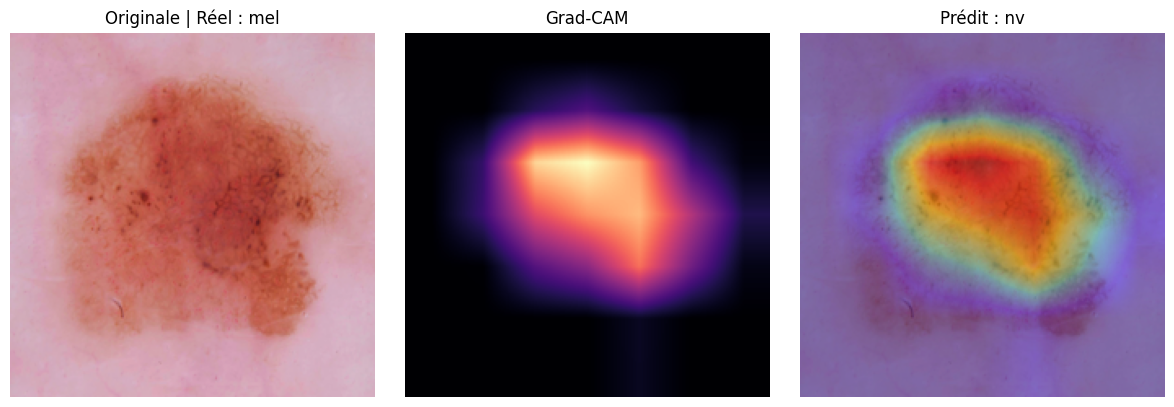

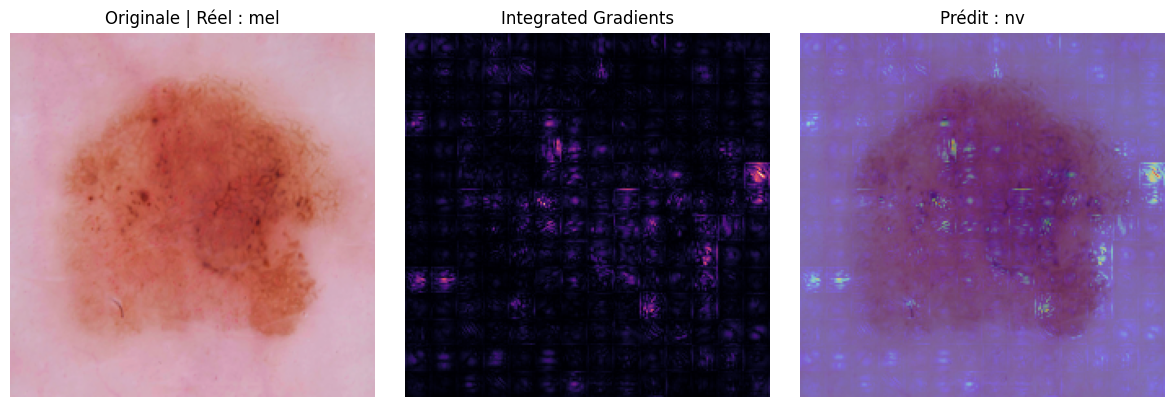

Grad-CAM sauvegardé : /kaggle/working/ham10000_Portfolio/xai/efficientnet_b0/ISIC_0024351.png
Integrated Gradients sauvegardé : /kaggle/working/ham10000_Portfolio/xai/vit_b_16/ISIC_0024351.png


In [11]:
# 1. Dossier de sauvegarde des cartes XAI
EXPLAIN_DIR = OUTPUT_ROOT / "xai"
EXPLAIN_DIR.mkdir(parents=True, exist_ok=True)


# 2. Fonction de visualisation
def save_explanation(image_path, heatmap, architecture,
                     image_id, method, true_class, predicted_class):

    # Charger l'image originale
    with Image.open(image_path) as img:
        original = np.array(
            img.convert("RGB").resize((IMAGE_SIZE, IMAGE_SIZE))
        )

    # Créer trois graphiques
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))

    # Image originale
    axes[0].imshow(original)
    axes[0].set_title(f"Originale | Réel : {true_class}")

    # Carte d'attribution
    axes[1].imshow(heatmap, cmap="magma", vmin=0, vmax=1)
    axes[1].set_title(method)

    # Superposition
    axes[2].imshow(original)
    axes[2].imshow(
        heatmap,
        cmap="jet",
        alpha=0.4,
        vmin=0,
        vmax=1
    )
    axes[2].set_title(f"Prédit : {predicted_class}")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()

    # Sauvegarder la figure
    output_folder = EXPLAIN_DIR / architecture
    output_folder.mkdir(parents=True, exist_ok=True)

    output_path = output_folder / f"{image_id}.png"

    fig.savefig(output_path, dpi=170, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    return output_path


# 3. Retrouver l'image testée précédemment
image_id = "ISIC_0024351"

row = parts["test"].set_index("image_id").loc[image_id]

# 4. Visualiser Grad-CAM pour EfficientNet-B0
path_gradcam = save_explanation(
    image_path=row["image_path"],
    heatmap=heatmap,
    architecture="efficientnet_b0",
    image_id=image_id,
    method="Grad-CAM",
    true_class="mel",
    predicted_class="nv"
)

# 5. Visualiser Integrated Gradients pour ViT-B/16
path_ig = save_explanation(
    image_path=row["image_path"],
    heatmap=ig_heatmap,
    architecture="vit_b_16",
    image_id=image_id,
    method="Integrated Gradients",
    true_class="mel",
    predicted_class="nv"
)

print("Grad-CAM sauvegardé :", path_gradcam)
print("Integrated Gradients sauvegardé :", path_ig)

### 7.2. Génération des dix figures


===== vit_b_16 =====


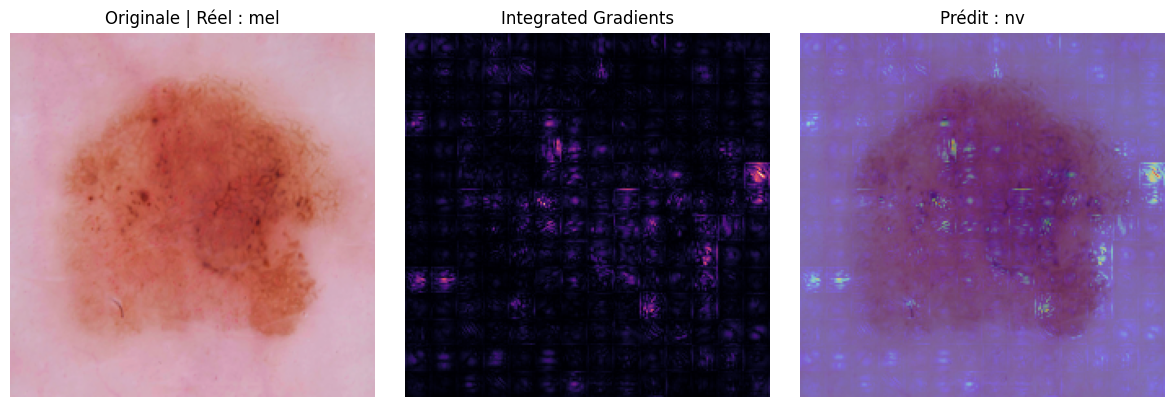

Enregistré : ISIC_0024351


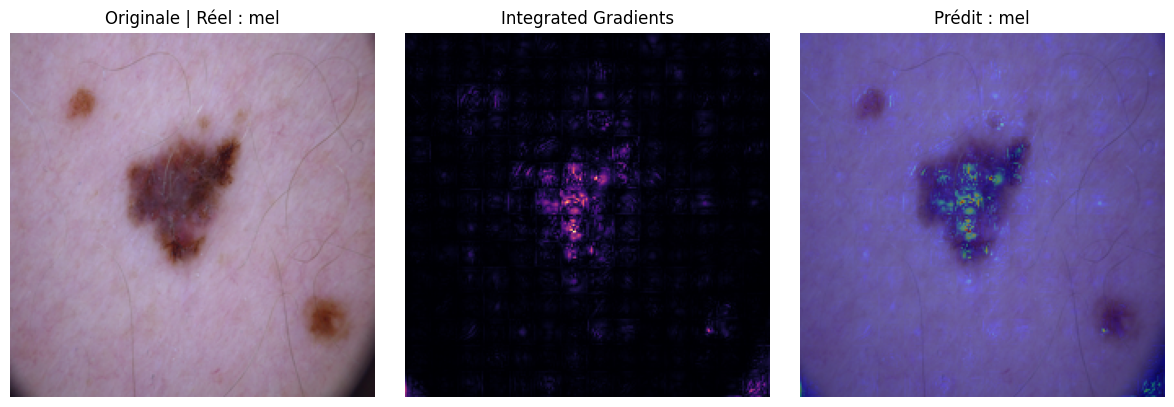

Enregistré : ISIC_0024315


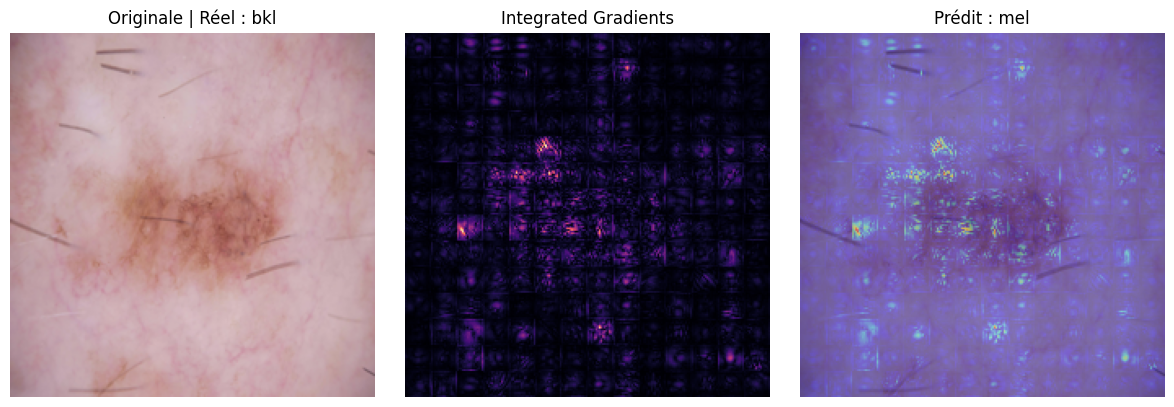

Enregistré : ISIC_0024422


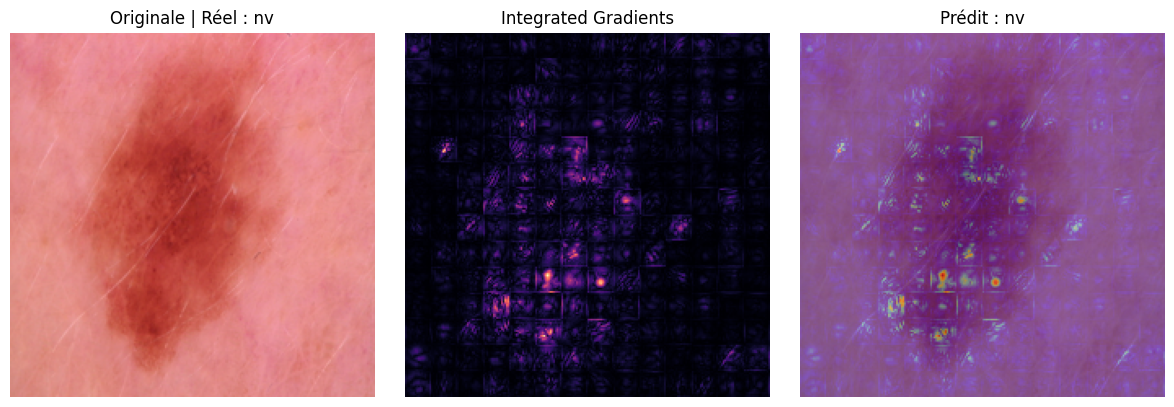

Enregistré : ISIC_0024325


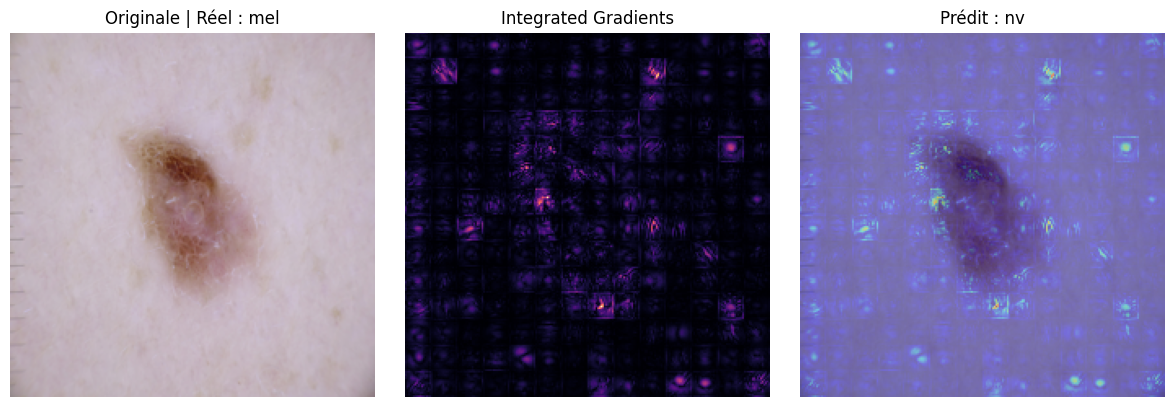

Enregistré : ISIC_0024481

===== efficientnet_b0 =====


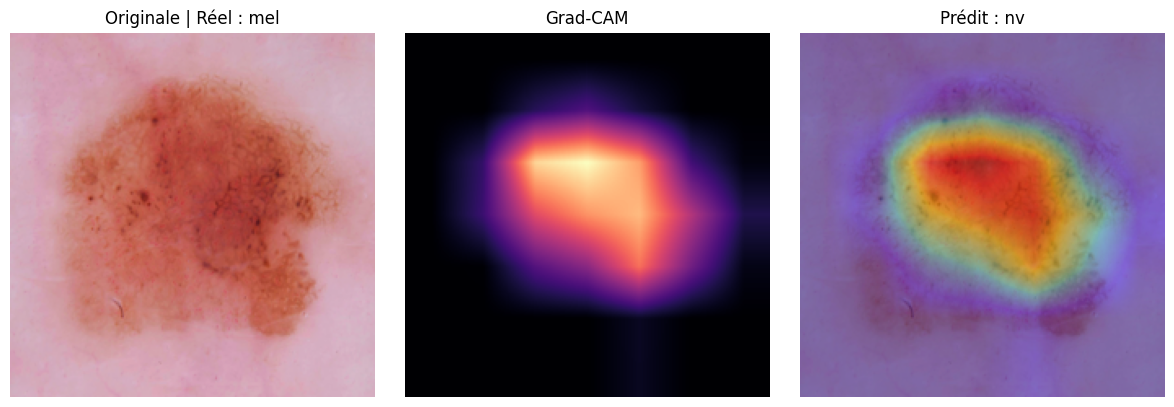

Enregistré : ISIC_0024351


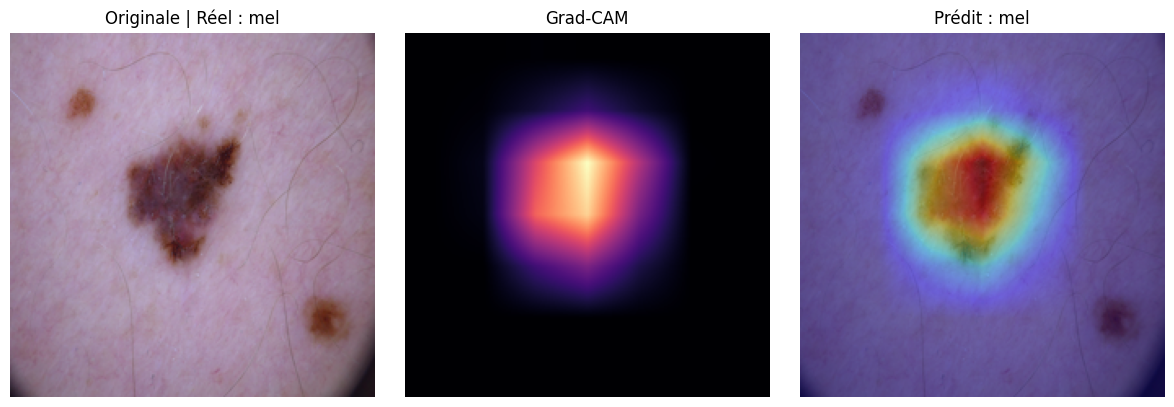

Enregistré : ISIC_0024315


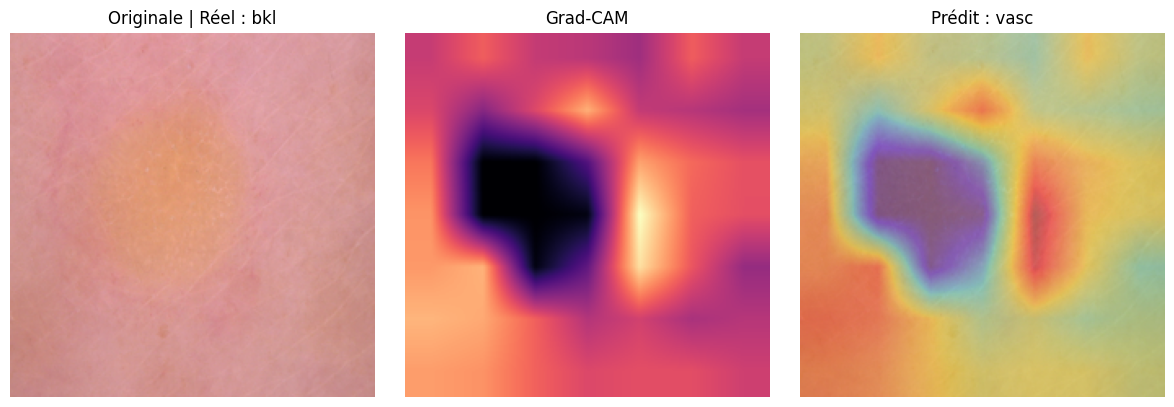

Enregistré : ISIC_0024337


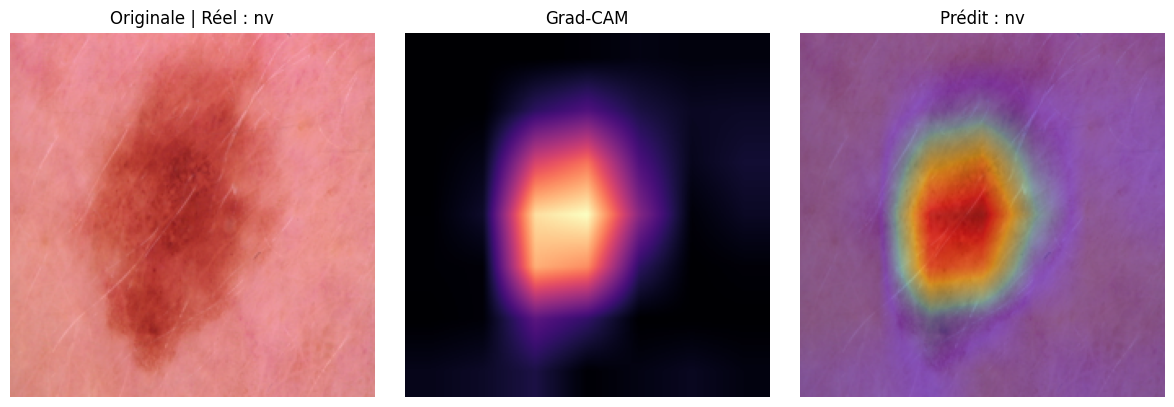

Enregistré : ISIC_0024325


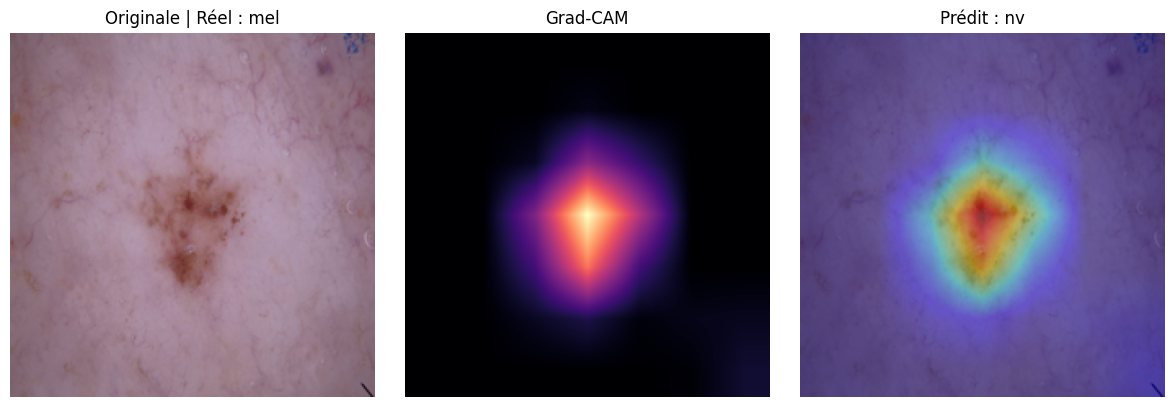

Enregistré : ISIC_0025409

Nombre de cartes : 10
Métadonnées : /kaggle/working/ham10000_Portfolio/xai/xai_examples.csv
Génération XAI terminée.


In [12]:
# 1. Libérer le GPU avant de traiter les modèles
vit_model = vit_model.cpu()
del vit_model
del efficientnet_model

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# 2. Préparer les résultats
records = []

# Retrouver rapidement une image dans le Test Set
image_indices = {
    image_id: i
    for i, image_id in enumerate(test_dataset.frame["image_id"])
}

# 3. Parcourir les deux architectures
for architecture in selected_archs:

    print(f"\n===== {architecture} =====")

    # Charger les prédictions et choisir 5 images
    predictions = pd.read_csv(
        METRICS_DIR / f"predictions_{architecture}.csv"
    )

    chosen = pick_cases(predictions, MAX_EXAMPLES_PER_ARCH)

    # Charger le modèle entraîné
    model, _, _ = load_checkpoint_model(architecture)

    # 4. Expliquer chaque image
    for _, row in chosen.iterrows():

        image_id = row["image_id"]
        index = image_indices[image_id]

        image, true_label = test_dataset[index]
        image_tensor = image.unsqueeze(0).to(DEVICE)

        # Vérifier la prédiction du checkpoint
        with torch.no_grad():
            predicted_label = model(
                image_tensor
            ).argmax(dim=1).item()

        assert CLASSES[true_label] == row["dx"]
        assert CLASSES[predicted_label] == row["predicted_dx"]

        # 5. Calculer l'explication XAI
        if architecture == "efficientnet_b0":

            attribution_map = compute_gradcam(
                model, image_tensor, predicted_label
            )
            method = "Grad-CAM"
            delta = None

        else:

            attribution_map, delta = compute_integrated_gradients(
                model, image_tensor, predicted_label
            )
            method = "Integrated Gradients"

        # 6. Afficher et sauvegarder la figure
        image_path = test_dataset.frame.iloc[index]["image_path"]

        figure_path = save_explanation(
            image_path=image_path,
            heatmap=attribution_map,
            architecture=architecture,
            image_id=image_id,
            method=method,
            true_class=row["dx"],
            predicted_class=row["predicted_dx"]
        )

        # 7. Enregistrer les métadonnées
        records.append({
            "architecture": architecture,
            "image_id": image_id,
            "true_class": row["dx"],
            "predicted_class": row["predicted_dx"],
            "correct": bool(row["dx"] == row["predicted_dx"]),
            "case_type": row["case_type"],
            "method": method,
            "ig_convergence_delta": delta,
            "figure": str(figure_path)
        })

        print("Enregistré :", image_id)

    # Libérer le modèle avant le suivant
    del model
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# 8. Sauvegarder le tableau des explications
xai_results = pd.DataFrame(records)

XAI_META = EXPLAIN_DIR / "xai_examples.csv"
xai_results.to_csv(XAI_META, index=False)

print("\nNombre de cartes :", len(xai_results))
print("Métadonnées :", XAI_META)
print("Génération XAI terminée.")

## 8. Analyse qualitative et limites

### 8.1. Analyse des prédictions expliquées

In [13]:
# 1. Charger les résultats XAI
xai_results = pd.read_csv(
    EXPLAIN_DIR / "xai_examples.csv"
)

# 2. Récupérer les probabilités du notebook 04
all_predictions = []

for architecture in selected_archs:

    predictions = pd.read_csv(
        METRICS_DIR / f"predictions_{architecture}.csv"
    )

    predictions["architecture"] = architecture

    all_predictions.append(
        predictions[
            ["architecture", "image_id",
             "confidence", "p_mel", "p_nv"]
        ]
    )

all_predictions = pd.concat(
    all_predictions,
    ignore_index=True
)

# 3. Associer chaque carte à sa prédiction
xai_analysis = xai_results.merge(
    all_predictions,
    on=["architecture", "image_id"],
    how="left",
    validate="one_to_one"
)

# 4. Vérifier les résultats
assert len(xai_analysis) == 10
assert xai_analysis["confidence"].notna().all()

# 5. Afficher le tableau
display(
    xai_analysis[
        ["architecture", "image_id",
         "true_class", "predicted_class",
         "correct", "confidence", "p_mel", "p_nv"]
    ].round(4)
)

print("Exemples analysés :", len(xai_analysis))
print("Analyse des prédictions : OK")

,architecture,image_id,true_class,predicted_class,correct,confidence,p_mel,p_nv
0,vit_b_16,ISIC_0024351,mel,nv,False,0.9887,0.0110,0.9887
1,vit_b_16,ISIC_0024315,mel,mel,True,0.9524,0.9524,0.0475
2,vit_b_16,ISIC_0024422,bkl,mel,False,0.6506,0.6506,0.2301
3,vit_b_16,ISIC_0024325,nv,nv,True,1.0000,0.0000,1.0000
4,vit_b_16,ISIC_0024481,mel,nv,False,0.9684,0.0007,0.9684
5,efficientnet_b0,ISIC_0024351,mel,nv,False,0.8691,0.1079,0.8691
6,efficientnet_b0,ISIC_0024315,mel,mel,True,0.9477,0.9477,0.0264
7,efficientnet_b0,ISIC_0024337,bkl,vasc,False,0.4174,0.0083,0.0854
8,efficientnet_b0,ISIC_0024325,nv,nv,True,0.9965,0.0014,0.9965
9,efficientnet_b0,ISIC_0025409,mel,nv,False,0.5159,0.3625,0.5159


Exemples analysés : 10
Analyse des prédictions : OK


### 8.2. Interprétation des résultats observés

D'après les résultats exécutés dans ce notebook, **10 images-modèles** ont été expliquées : cinq pour ViT-B/16 et cinq pour EfficientNet-B0. L'échantillon est orienté volontairement vers les réussites et les erreurs : **six prédictions sont incorrectes et quatre sont correctes**. Ces proportions **ne représentent pas** la performance des modèles sur l'ensemble du Test Set.

**Cas commun `ISIC_0024351` — mélanome (`mel`) confondu avec  (`nv`) :**

| Architecture | Classe réelle | Classe prédite | Confiance softmax | `p_mel` |
|---|---|---|---:|---:|
| ViT-B/16 | mel | nv | 98,87 % | 1,10 % |
| EfficientNet-B0 | mel | nv | 86,91 % | 10,79 % |

**Autres prédictions observées :**

- `ISIC_0024315` (`mel -> mel`) est correctement classée par les deux modèles : confiance **95,24 %** pour ViT et **94,77 %** pour EfficientNet.
- `ISIC_0024325` (`nv -> nv`) est correctement classée par les deux modèles : confiance **100,00 %** pour ViT et **99,65 %** pour EfficientNet.
- `ISIC_0024422` (`bkl -> mel`) est une erreur de ViT avec **65,06 %** de confiance.
- `ISIC_0024337` (`bkl -> vasc`) est une erreur d'EfficientNet avec **41,74 %** de confiance.
- `ISIC_0024481` (`mel -> nv`) est une erreur de ViT avec **96,84 %** de confiance.
- `ISIC_0025409` (`mel -> nv`) est une erreur d'EfficientNet avec **51,59 %** de confiance.

### 8.3. Lecture des cartes XAI

Sur la figure examinée pour `ISIC_0024351`, la carte **Grad-CAM** met surtout en évidence une zone centrale à supérieure de la lésion. La carte **Integrated Gradients** montre des attributions plus dispersées, avec une structure en grille visible. Cette différence est **descriptive**, et ne prouve ni une meilleure interprétabilité d'un modèle ni la pertinence dermatologique des zones identifiées.

Deux précautions méthodologiques sont essentielles :

1. Les cartes affichées ne représentent pas la même grandeur : **Grad-CAM positif** versus **magnitude absolue d'Integrated Gradients**. De plus, leur normalisation individuelle interdit toute comparaison quantitative directe des intensités.
2. Sur le modèle final (**ViT-B/16 atteignant 78.55% de Macro-F1**), le convergence_delta calculé avec **24 étapes** est de **0.30915** Cette valeur indique que l'approximation numérique est moins précise que sur les versions préliminaires, probablement due à la complexité accrue des gradients du modèle optimisé. **Perspective** : pour une analyse XAI plus fiable sur ce modèle final, il serait recommandé d'augmenter le nombre d'étapes d'intégration (ex: 128 étapes) afin de réduire cet écart.

### 8.4. Limites et perspectives

- Les dix exemples sont **qualitatifs** et choisis de manière ciblée, ils ne constituent pas une validation statistique de l'explicabilité.
- Une carte XAI n'est **ni une segmentation de lésion**, ni une preuve causale, ni une justification clinique.
- L'évaluation est réalisée sur le Test Set de **HAM10000**, une validation externe reste nécessaire pour juger la robustesse à d'autres populations, appareils et conditions d'acquisition.
- Les modèles peuvent se tromper avec un score softmax élevé : la **calibration des prédictions** et l'analyse des faux négatifs du mélanome constituent des suites importantes.
- Des contrôles de robustesse des explications (changement de baseline IG, nombre d'étapes, perturbations contrôlées ou tests d'occlusion) renforceraient les conclusions.

### 8.5. Conclusion

Le notebook démontre la faisabilité d'une analyse XAI reproductible, fondée sur les checkpoints fine-tunés et des partitions sans recouvrement de `lesion_id`. **Grad-CAM** fournit une attribution spatiale positive pour EfficientNet-B0, tandis qu'**Integrated Gradients** attribue des contributions aux pixels d'entrée du ViT-B/16.